**Khảo sát dữ liệu cho bài toán xấp xỉ Gaussian hai chiều**

Notebook kiểm tra hàm Gaussian, tạo và thống kê các tập dữ liệu, sau đó lưu các biểu đồ vào `graphs/data/`.

In [1]:
import sys
from pathlib import Path

import numpy as np
from IPython.display import Image, display
from scipy.stats import multivariate_normal

# Tìm thư mục dự án từ thư mục hiện tại.
here = Path.cwd().resolve()
codes = next(
    (
        path / "codes"
        for path in (here, *here.parents)
        if (path / "codes" / "common" / "config.py").is_file()
    ),
    None,
)
if codes is None:
    raise RuntimeError(
        "Could not find codes/common/config.py. Run this notebook from the project directory."
    )
sys.path.insert(0, str(codes))

from common.config import (
    C_MAT,
    GRAPHS_DIR,
    LOGS_DIR,
    MU,
    N_TEST,
    N_TRAIN_POOL,
    N_VAL,
    ROOT,
    ensure_dirs,
)
from common.data import describe_dataset, gaussian_2d, make_dataset
from common.plots import plot_distributions, plot_scatter3d, plot_true_surface

ensure_dirs()
print(f"Project root: {ROOT}")

Project root: C:\Users\qhoan\.vscode\Coding\Data Science\(!!!) 4.HK1 - Học sâu (Python)\Buổi thực hành số 5 (MLP Introduction)\Lab05b - Function Approximation


## **Bước 1 - Kiểm tra công thức Gaussian**

So sánh hàm tự cài đặt với SciPy trên một số điểm kiểm tra, đồng thời đối chiếu giá trị tại gốc với công thức lý thuyết.

In [2]:
probe_points = np.array(
    [[0.0, 0.0], [1.0, -2.0], [-1.5, 3.0]],
    dtype=float,
)
implemented_values = gaussian_2d(probe_points)
scipy_values = multivariate_normal(mean=MU, cov=C_MAT).pdf(probe_points)
max_error = float(np.max(np.abs(implemented_values - scipy_values)))

np.testing.assert_allclose(
    implemented_values,
    scipy_values,
    rtol=1e-12,
    atol=1e-12,
    err_msg="The Gaussian implementation does not match SciPy.",
)

det_cov = float(np.linalg.det(C_MAT))
theoretical_at_origin = 1.0 / (2.0 * np.pi * np.sqrt(det_cov))
implemented_at_origin = float(gaussian_2d(np.zeros(2))[0])
np.testing.assert_allclose(
    implemented_at_origin,
    theoretical_at_origin,
    rtol=1e-12,
    atol=1e-12,
    err_msg="The Gaussian value at the origin does not match the formula.",
)

print(f"Maximum absolute error vs. SciPy: {max_error:.2e}")
print(f"Theoretical f(0): {theoretical_at_origin:.6f}")
print(f"Implemented f(0): {implemented_at_origin:.6f}")

Maximum absolute error vs. SciPy: 5.55e-17
Theoretical f(0): 0.269021
Implemented f(0): 0.269021


## **Bước 2 - Tạo và lưu dữ liệu**

Tạo các tập train, validation và test theo seed cấu hình; lưu dữ liệu CSV trong `logs/data/`. Các điểm dùng để kiểm tra công thức ở bước trước không lấy từ tập test.

In [3]:
data = make_dataset(save=True)
expected_sizes = {
    "train": N_TRAIN_POOL,
    "val": N_VAL,
    "test": N_TEST,
}

for split, expected_size in expected_sizes.items():
    X, y = data[split]
    if X.shape != (expected_size, 2) or y.shape != (expected_size,):
        raise ValueError(f"Unexpected {split} data shapes: X={X.shape}, y={y.shape}.")
    print(f"{split.title()} samples: {len(y)}")

Train samples: 2000
Val samples: 400
Test samples: 100


## **Bước 3 - Thống kê dữ liệu**

Tính số lượng, trung bình, độ lệch chuẩn, giá trị nhỏ nhất và lớn nhất của `x1`, `x2`, `y` trên từng tập; lưu bảng vào `logs/data_stats.csv`.

In [4]:
stats = describe_dataset(data)
stats_path = LOGS_DIR / "data_stats.csv"
stats.to_csv(stats_path, index=False)
print(f"Dataset statistics saved to: {stats_path}")
stats.round(4)

Dataset statistics saved to: C:\Users\qhoan\.vscode\Coding\Data Science\(!!!) 4.HK1 - Học sâu (Python)\Buổi thực hành số 5 (MLP Introduction)\Lab05b - Function Approximation\logs\data_stats.csv


,split,variable,n,mean,std,min,max
0,train,x1,2000,0.0113,1.1615,-1.9979,1.9977
1,train,x2,2000,-0.0111,2.3060,-3.9949,3.9953
2,train,y,2000,0.0300,0.0572,0.0000,0.2676
3,val,x1,400,-0.1071,1.1737,-1.9806,1.9991
4,val,x2,400,-0.1915,2.2846,-3.9926,3.9812
5,val,y,400,0.0336,0.0608,0.0000,0.2688
6,test,x1,100,-0.2916,1.0776,-1.9815,1.9832
7,test,x2,100,-0.1553,2.4295,-3.9477,3.8987
8,test,y,100,0.0327,0.0619,0.0000,0.2523


## **Bước 4 - Vẽ và lưu biểu đồ**

Vẽ 500 điểm train, bề mặt Gaussian thật và phân bố các biến. Các hình được lưu trong `graphs/data/`.

In [5]:
X_train, y_train = data["train"]
data_graphs_dir = GRAPHS_DIR / "data"

plot_scatter3d(
    X_train[:500],
    y_train[:500],
    data_graphs_dir / "scatter3d_train.png",
)
plot_true_surface(data_graphs_dir / "true_surface.png")
plot_distributions(
    X_train,
    y_train,
    data_graphs_dir / "distributions_train.png",
)

  -> Saved figure: C:\Users\qhoan\.vscode\Coding\Data Science\(!!!) 4.HK1 - Học sâu (Python)\Buổi thực hành số 5 (MLP Introduction)\Lab05b - Function Approximation\graphs\data\scatter3d_train.png


  -> Saved figure: C:\Users\qhoan\.vscode\Coding\Data Science\(!!!) 4.HK1 - Học sâu (Python)\Buổi thực hành số 5 (MLP Introduction)\Lab05b - Function Approximation\graphs\data\true_surface.png


  -> Saved figure: C:\Users\qhoan\.vscode\Coding\Data Science\(!!!) 4.HK1 - Học sâu (Python)\Buổi thực hành số 5 (MLP Introduction)\Lab05b - Function Approximation\graphs\data\distributions_train.png


## **Bước 5 - Xem lại các biểu đồ**

Hiển thị các hình vừa tạo để kiểm tra trực quan dữ liệu và hàm mục tiêu.

scatter3d_train.png


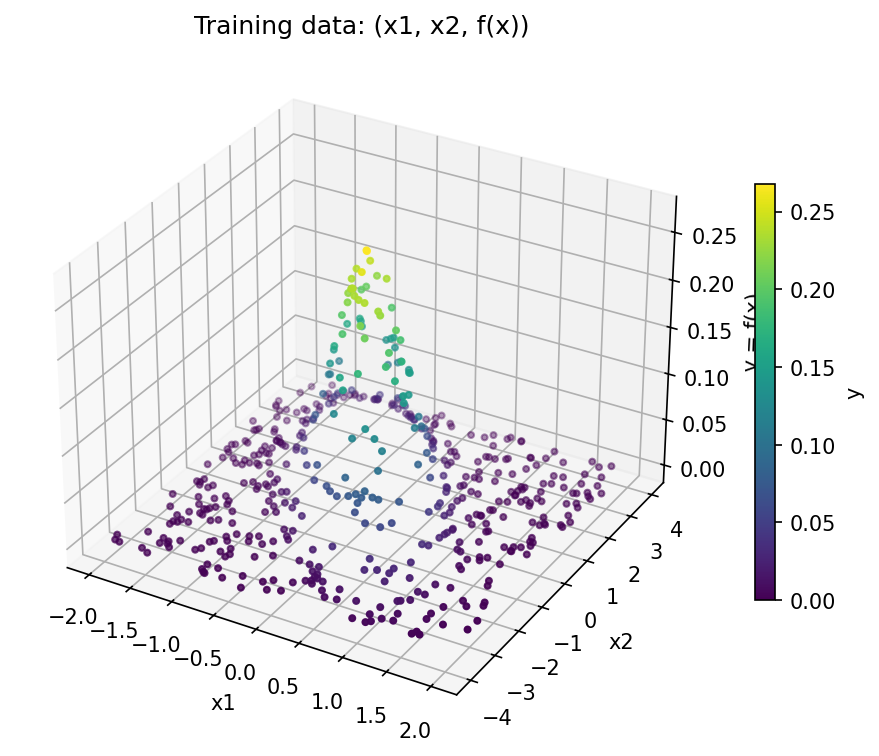

true_surface.png


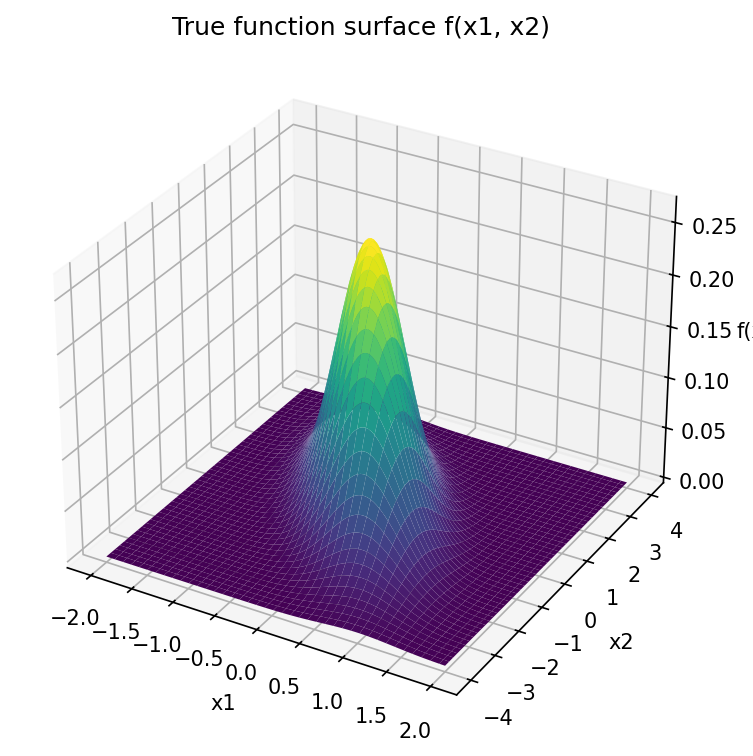

distributions_train.png


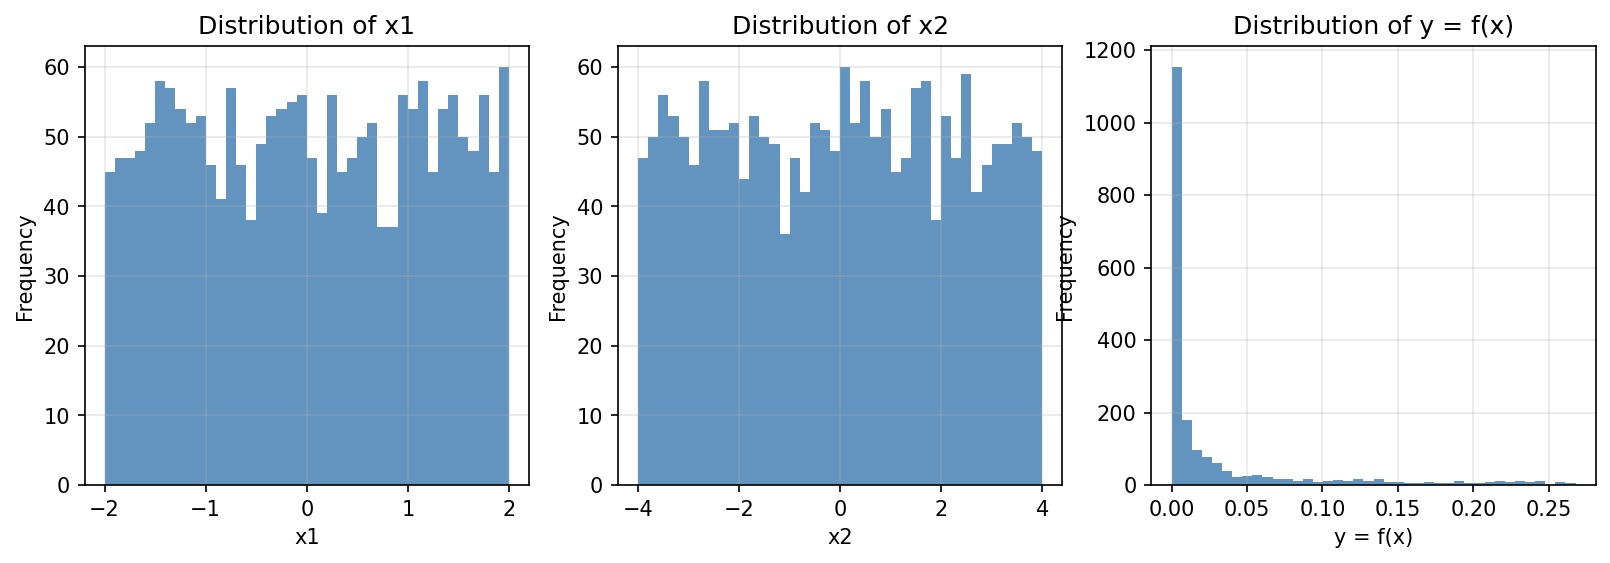

In [6]:
figure_names = [
    "scatter3d_train.png",
    "true_surface.png",
    "distributions_train.png",
]

for name in figure_names:
    image_path = data_graphs_dir / name
    if not image_path.is_file():
        raise FileNotFoundError(f"Expected figure was not created: {image_path}")
    print(name)
    display(Image(filename=str(image_path), width=600))

# <center>**HẾT**<center>